# 01 — Données et volatilité historique (S2)

**Objectif** : télécharger 2 ans de cours de clôture ajustés d'AAPL, calculer les rendements logarithmiques et la volatilité historique annualisée, qui sert d'entrée `σ` au pricer.

**Formules** : rendement `r_t = ln(S_t / S_{t-1})` ; volatilité historique `σ = std(r_t, ddof=1) × √252` (252 jours de bourse par an).

In [1]:
import sys, os
sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
os.makedirs("../docs/figures", exist_ok=True)
from data import load_prices_info, simulate_gbm_prices, log_returns, historical_volatility, rolling_realized_vol

## 1. Chargement
Ordre : yfinance, sinon le CSV de repli versionné (`data/aapl_2y_fallback.csv`), sinon une simulation GBM **étiquetée comme telle**. La variable `SOURCE` dit d'où viennent les chiffres : un résultat présenté au professeur doit afficher `yfinance` ou `csv`.

In [2]:
try:
    prices, SOURCE = load_prices_info("AAPL", "2y", csv_fallback="../data/aapl_2y_fallback.csv")
except (RuntimeError, FileNotFoundError):
    prices, SOURCE = simulate_gbm_prices(S0=100.0, mu=0.05, sigma=0.25, n=504), "simulation GBM (données NON réelles)"
print("SOURCE =", SOURCE)

SOURCE = simulation GBM (données NON réelles)


## 2. Contrôle des données

In [3]:
print("observations :", len(prices))
print("période      :", prices.index[0].date(), "→", prices.index[-1].date())
print("manquantes   :", int(prices.isna().sum()))
print("dernier cours:", round(float(prices.iloc[-1]), 2))

observations : 505
période      : 2024-12-05 → 2026-11-11
manquantes   : 0
dernier cours: 93.68


## 3. Rendements et volatilité historique

In [4]:
r = log_returns(prices)
SIGMA_HIST = historical_volatility(r)
vol5 = rolling_realized_vol(r, window=5)
print(f"rendement moyen journalier : {r.mean():.5f}")
print(f"σ historique annualisée     : {SIGMA_HIST:.4f}  ({SIGMA_HIST:.1%})")

rendement moyen journalier : -0.00013
σ historique annualisée     : 0.2404  (24.0%)


## 4. Graphiques
La volatilité glissante sur 5 jours montre le **regroupement** de la volatilité (les fortes variations se suivent) : c'est ce que le LSTM de la S4 cherchera à prévoir.

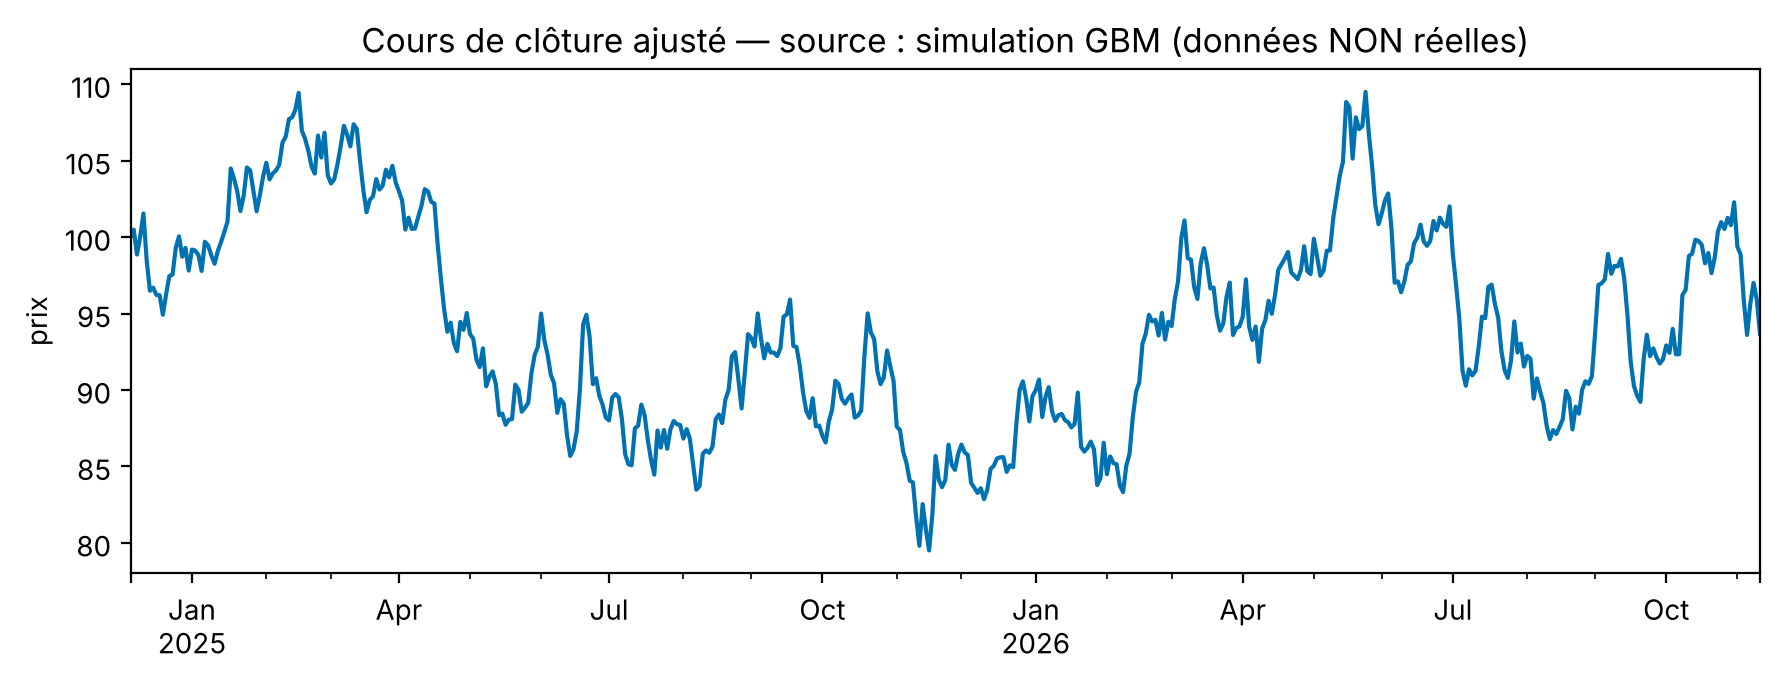

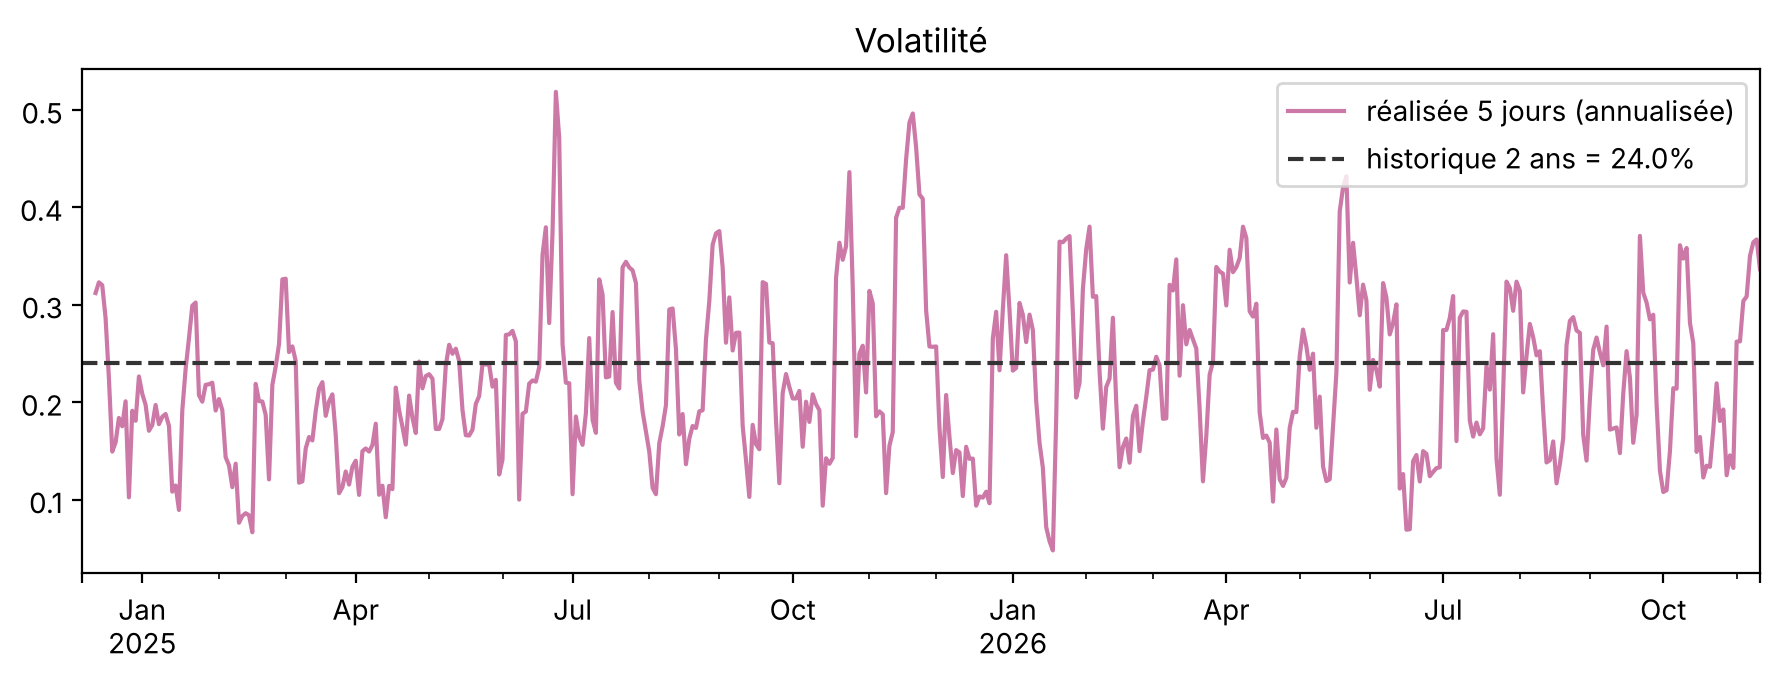

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.5))
prices.plot(ax=ax, color="#0072B2"); ax.set_title(f"Cours de clôture ajusté — source : {SOURCE}"); ax.set_ylabel("prix")
fig.tight_layout(); fig.savefig("../docs/figures/fig_01_prix.png", dpi=150); plt.show()
fig, ax = plt.subplots(figsize=(9, 3.5))
vol5.plot(ax=ax, color="#CC79A7", label="réalisée 5 jours (annualisée)")
ax.axhline(SIGMA_HIST, color="#333333", ls="--", label=f"historique 2 ans = {SIGMA_HIST:.1%}")
ax.set_title("Volatilité"); ax.legend(); fig.tight_layout(); fig.savefig("../docs/figures/fig_02_vol_realisee_5j.png", dpi=150); plt.show()

## 5. Résultat transmis au notebook 02

In [6]:
pd.Series({"S0": float(prices.iloc[-1]), "sigma_hist": SIGMA_HIST, "source": SOURCE}).to_json("../docs/figures/parametres_aapl.json")
print({"S0": round(float(prices.iloc[-1]), 2), "sigma_hist": round(SIGMA_HIST, 4), "source": SOURCE})

{'S0': 93.68, 'sigma_hist': 0.2404, 'source': 'simulation GBM (données NON réelles)'}
